# Predicting the final size of a wildfire at discovery

## 1. Data

* **FPA FOD-Attributes**, https://zenodo.org/records/8381129 (description: https://essd.copernicus.org/articles/16/3045/2024/). More than 2.3 million US wildfire ignitions (1992–2020) described by nearly 270 physical, biological, social and administrative attributes, in one CSV file per year.
* **How and why:** FPA FOD (USDA Forest Service) gathers the wildfire reports of federal, state and local agencies into one national database, used for fire management planning and research. Pourmohamad et al. (2024) added the attributes by extracting, at the place and date of each ignition, values from 24 sources (weather, vegetation, terrain, population, firefighting resources).
* **Application domain:** wildfire risk and emergency management, close to the Copernicus Emergency Management Service (EFFIS in Europe).
* **Scope:** years 2019 and 2020 (one CSV file each, reduced to the 37 columns we use by `preprocess_csv.py`), all states of USA except Alaska, Hawaii and Puerto Rico.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.concat([pd.read_csv(f"{year}_FPA_FOD_light.csv", low_memory=False) for year in (2019, 2020)], ignore_index=True)
df = df[~df["STATE"].isin(["AK", "HI", "PR"])].reset_index(drop=True)
df.shape

(134635, 37)

## 2. Learning task

* **Question:** when a fire is discovered, what will its final size be?
* **Task:** supervised multi-class classification with 5 ordered classes. One observation = one fire.
* **Output `y`:** class of the final burned area `FIRE_SIZE`, built from the official classes A to G:

| `y` | Class | Official classes | Final size |
|---|---|---|---|
| 0 | very small | A | less than 0.26 acres (0.1 ha) |
| 1 | small | B | 0.26 to 9.9 acres (0.1 to 4 ha) |
| 2 | medium | C | 10 to 99.9 acres (4 to 40 ha) |
| 3 | medium-large | D | 100 to 299 acres (40 to 121 ha) |
| 4 | large | E, F, G | 300 acres or more (121 ha or more) |

**Why these classes:**
* They are the official size classes of the NWCG (*National Wildfire Coordinating Group*), used by US firefighting agencies and already present in FPA FOD (`FIRE_SIZE_CLASS`).
* Classes E, F and G are merged because they are too rare on their own.
* Predicting a class rather than the exact area is more robust: `FIRE_SIZE` ranges from 0.0007 to 589,368 acres.

In [2]:
CLASSES = ["very small (A)", "small (B)", "medium (C)", "medium-large (D)", "large (E-G)"]

y = pd.cut(df["FIRE_SIZE"], bins=[0, 0.26, 10, 100, 300, np.inf], right=False, labels=False).rename("size_class")
y.value_counts().sort_index().rename(index=dict(enumerate(CLASSES)))

size_class
very small (A)      65104
small (B)           55648
medium (C)          10490
medium-large (D)     1681
large (E-G)          1712
Name: count, dtype: int64

The classes are highly imbalanced: very small and small fires make up 90% of all fires, against 8% for medium, 1.2% for medium-large and 1.3% for large fires.

## 3. Explanatory variables

We keep only variables **known at the time of discovery** (30 in total):

| Theme | Variables | Meaning | Type |
|---|---|---|---|
| Location | `LATITUDE`, `LONGITUDE` | coordinates of the ignition point (°) | numerical |
| Time | `DOY_SIN`, `DOY_COS`, `DISCOVERY_HOUR` | day of year with cyclical encoding: sine and cosine of 2π × day / 366. 31 December is thus close to 1 January. Hour of discovery (0 to 23) | numerical, derived |
| Daily weather | `pr`, `tmmx`, `rmin`, `vs`, `vpd` | precipitation (mm), maximum temperature (K), minimum relative humidity (%), wind speed (m/s), vapour pressure deficit (kPa) | numerical |
| Fire danger | `erc`, `bi`, `fm100`, `fm1000` | fire danger indices (energy release, burning intensity), dead fuel moisture (%) | numerical |
| Climate | `Aridity_index` | annual precipitation divided by potential evapotranspiration (low = arid) | numerical |
| Vegetation | `MOD_NDVI_12m_mean` | mean MODIS NDVI over the 12 months before the fire (-1 to 1) | numerical, derived |
| Land cover | `Land_Cover_1km_main` | most frequent NLCD class within 1 km | **categorical** (15 classes), derived |
| Fire regime | `FRG_1km_main` | most frequent LANDFIRE fire regime group within 1 km | **categorical** (10 classes), derived |
| Terrain | `Elevation`, `Slope`, `TRI` | elevation (m), slope (°), terrain ruggedness | numerical |
| Human presence | `Popo_1km`, `GHM`, `Distance_to_road` | mean population density within 1 km, global human modification index (0 to 1), minimum of the six road distance columns | numerical |
| Firefighting | `No_FireStation_10.0km`, `SDI`, `NPL`, `GACC_PL` | fire stations within 10 km, suppression difficulty (static map computed before the fire), national and regional preparedness levels on the discovery day (1 to 5) | numerical, ordinal |
| Social, land management | `RPL_THEMES`, `GAP_Sts` | overall social vulnerability (0 to 1), protection status of the land (1 to 4) | numerical, ordinal |

The derived variables are computed from columns of the dataset. `MOD_NDVI_12m` stores the 12 monthly values in a single text cell. `Land_Cover_1km` and `FRG_1km` store the most frequent classes with their share (for example `52(58%) / 82(17%) / 71(13%)`): we keep the first, most frequent code. `DISCOVERY_HOUR` is the hhmm discovery time divided by 100 (1430 gives 14). `Distance_to_road` is the minimum of the six `road_*_dis` columns, ignoring missing values.

**Columns excluded because they reveal the answer or are only known after the fire:** `FIRE_SIZE_CLASS` (almost the target itself), `CONT_DATE` and `CONT_TIME` (containment), the cause, `MTBS_ID` and the ICS-209 identifiers (exist only for large fires), the 5-day weather windows (include the 2 days after ignition).

In [3]:
NUM_FEATURES = ["LATITUDE", "LONGITUDE", "DOY_SIN", "DOY_COS", "DISCOVERY_HOUR",
                "pr", "tmmx", "rmin", "vs", "vpd",
                "erc", "bi", "fm100", "fm1000",
                "Aridity_index", "MOD_NDVI_12m_mean",
                "Elevation", "Slope", "TRI",
                "Popo_1km", "GHM", "Distance_to_road",
                "No_FireStation_10.0km", "SDI", "NPL", "GACC_PL",
                "RPL_THEMES", "GAP_Sts"]
CAT_FEATURES = ["Land_Cover_1km_main", "FRG_1km_main"]

ROADS = ["road_county_dis", "road_interstate_dis", "road_common_name_dis",
         "road_other_dis", "road_state_dis", "road_US_dis"]

# Derived variables, computed from existing columns
derived = pd.DataFrame({
    "DOY_SIN": np.sin(2 * np.pi * df["DISCOVERY_DOY"] / 366),
    "DOY_COS": np.cos(2 * np.pi * df["DISCOVERY_DOY"] / 366),
    "DISCOVERY_HOUR": df["DISCOVERY_TIME"] // 100,
    "MOD_NDVI_12m_mean": df["MOD_NDVI_12m"].str.replace("'", "").str.split(expand=True).astype(float).mean(axis=1),
    "Distance_to_road": df[ROADS].min(axis=1),
    "Land_Cover_1km_main": df["Land_Cover_1km"].str.split("(").str[0],
    "FRG_1km_main": df["FRG_1km"].str.split("(").str[0],
})

print("Number of features:", len(NUM_FEATURES) + len(CAT_FEATURES))

X = df.join(derived)[NUM_FEATURES + CAT_FEATURES].copy()

Number of features: 30


## 4. Descriptive analysis

### Preliminary cleaning

* Some columns encode missing data with an extreme value (-3.4e36 for `SDI`, -3.4e38 for `GHM`, -999 for `RPL_THEMES`). These values are replaced with missing values.
* `No_FireStation_10.0km` is empty when there is no fire station within the radius: we replace it with 0.
* In `FRG_1km_main`, the code -9999 (27 fires) means "no data". It is kept as a separate category.
* `DISCOVERY_HOUR` and `Distance_to_road` are often empty. They are imputed in section 5.

The table below gives the main statistics of the numerical variables and their share of missing values.

In [4]:
X[NUM_FEATURES] = X[NUM_FEATURES].mask(X[NUM_FEATURES] <= -999)
X["No_FireStation_10.0km"] = X["No_FireStation_10.0km"].fillna(0)

stats = X[NUM_FEATURES].describe().T[["mean", "std", "min", "50%", "max"]]
stats["missing_%"] = X[NUM_FEATURES].isna().mean() * 100
stats.round(2)

,mean,std,min,50%,max,missing_%
LATITUDE,38.10,5.23,24.68,37.67,49.00,0.00
LONGITUDE,-98.62,15.72,-124.71,-98.12,-66.99,0.00
DOY_SIN,0.03,0.73,-1.00,-0.02,1.00,0.00
DOY_COS,-0.28,0.63,-1.00,-0.42,1.00,0.00
DISCOVERY_HOUR,14.06,4.58,0.00,14.00,23.00,24.43
pr,1.23,4.77,0.00,0.00,164.30,0.00
tmmx,298.07,8.83,252.50,298.80,321.80,0.00
rmin,29.31,13.99,1.00,28.30,100.00,0.00
vs,3.88,1.63,0.30,3.60,16.50,0.00
vpd,1.37,0.91,0.00,1.13,7.11,0.00


The table above shows that most variables have no missing values. The exceptions are `DISCOVERY_HOUR` (24%) and `Distance_to_road` (31%), imputed in section 5. The scales are very different (temperatures around 298 K, elevation up to 3,677 m, NDVI between -0.3 and 0.9), so standardisation is planned in section 5. Several variables are highly skewed: daily precipitation is zero for more than half of the fires (median 0, maximum 164 mm), and population density within 1 km has a median of 0.17 for a maximum of 310.

### Figure 1: where each class of fire occurs

The figure below shows the location of the 2019 and 2020 fires by class.

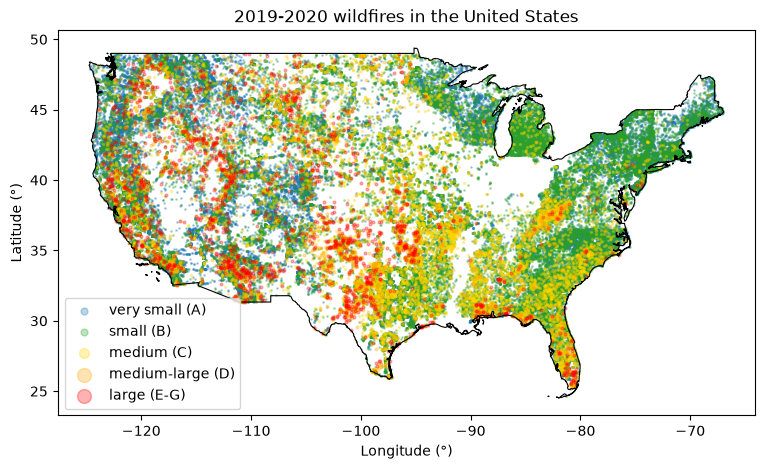

In [5]:
contour = pd.read_csv("contour_us.csv")

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df.loc[y == 0, "LONGITUDE"], df.loc[y == 0, "LATITUDE"], s=1, c="tab:blue", label="very small (A)", alpha=0.3)
ax.scatter(df.loc[y == 1, "LONGITUDE"], df.loc[y == 1, "LATITUDE"], s=1, c="tab:green", label="small (B)", alpha=0.3)
ax.scatter(df.loc[y == 2, "LONGITUDE"], df.loc[y == 2, "LATITUDE"], s=2, c="gold", label="medium (C)", alpha=0.3)
ax.scatter(df.loc[y == 3, "LONGITUDE"], df.loc[y == 3, "LATITUDE"], s=4, c="orange", label="medium-large (D)", alpha=0.3)
ax.scatter(df.loc[y == 4, "LONGITUDE"], df.loc[y == 4, "LATITUDE"], s=4, c="red", label="large (E-G)", alpha=0.3)
ax.plot(contour["lon"], contour["lat"], c="black", lw=0.8)
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.set_title("2019-2020 wildfires in the United States")
ax.legend(markerscale=5)
plt.show()

The figure above shows that the spatial distribution depends on the class (47% of all fires are west of longitude -100°):

* **very small (A)**: more often in the West (62%)
* **small (B) and medium (C)**: mostly in the East (31% and 34% in the West)
* **medium-large (D)**: on both sides (54% in the West)
* **large (E-G)**: mostly in the West (75%), with clusters in the Southern Great Plains and Florida

Location is therefore informative, but a model may learn these regional differences rather than the causes of fire spread.

### Figure 2: seasonality

The figure below shows the number of fires per month (left) and the share of medium-large and large fires per month (right).

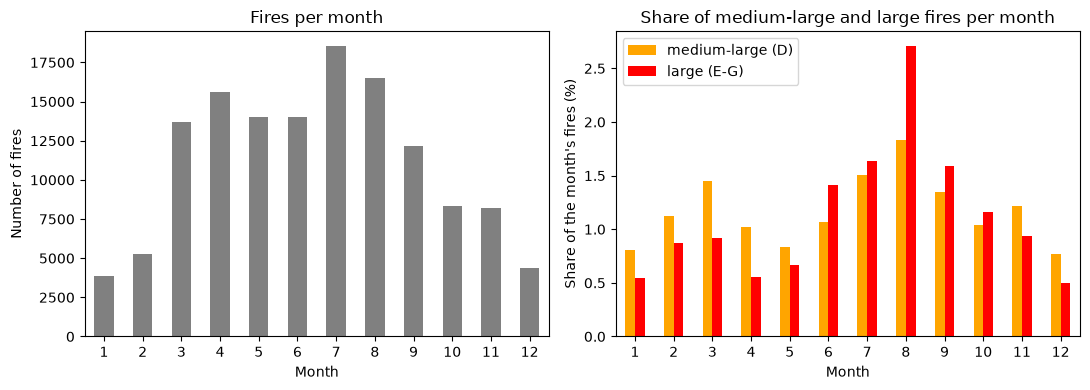

In [6]:
month = pd.to_datetime(df["DISCOVERY_DATE"]).dt.month

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
month.value_counts().sort_index().plot.bar(ax=axes[0], color="gray", rot=0)
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of fires")
axes[0].set_title("Fires per month")
share = pd.crosstab(month, y, normalize="index")[[3, 4]] * 100
share.columns = ["medium-large (D)", "large (E-G)"]
share.plot.bar(ax=axes[1], color=["orange", "red"], rot=0)
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Share of the month's fires (%)")
axes[1].set_title("Share of medium-large and large fires per month")
plt.tight_layout()
plt.show()

The figure above shows that fires are numerous from March to August, but that large fires are proportionally more frequent in summer.
The share of medium-large fires varies less. This seasonality justifies using the day of year as a variable (`DOY_SIN`, `DOY_COS`) and testing on a full year (section 6).

### Figure 3: selected variables by class

The figure below compares the distribution of four variables across the five size classes. Outliers are not shown.

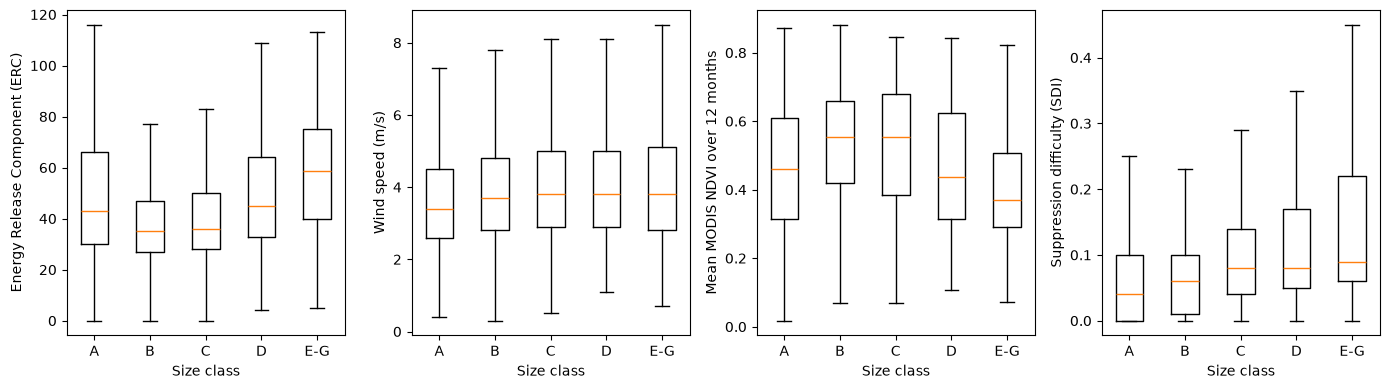

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col, label in zip(axes,
                          ["erc", "vs", "MOD_NDVI_12m_mean", "SDI"],
                          ["Energy Release Component (ERC)", "Wind speed (m/s)", "Mean MODIS NDVI over 12 months", "Suppression difficulty (SDI)"]):
    ax.boxplot([X.loc[y == k, col].dropna() for k in range(5)], showfliers=False)
    ax.set_xticks(range(1, 6), ["A", "B", "C", "D", "E-G"])
    ax.set_xlabel("Size class")
    ax.set_ylabel(label)
plt.tight_layout()
plt.show()

The figure above shows that large fires (E-G) tend to occur in dry conditions (ERC) and in less green vegetation (NDVI).
Suppression difficulty increases with the class, and wind speed slightly. 
Very small fires (A) do not follow the trend for ERC, their median is higher than for classes B and C. 
The distributions overlap widely, no single variable separates the classes, which justifies a model that combines them.

### Figure 4: correlations between variables

The figure below shows the correlation between the numerical variables.

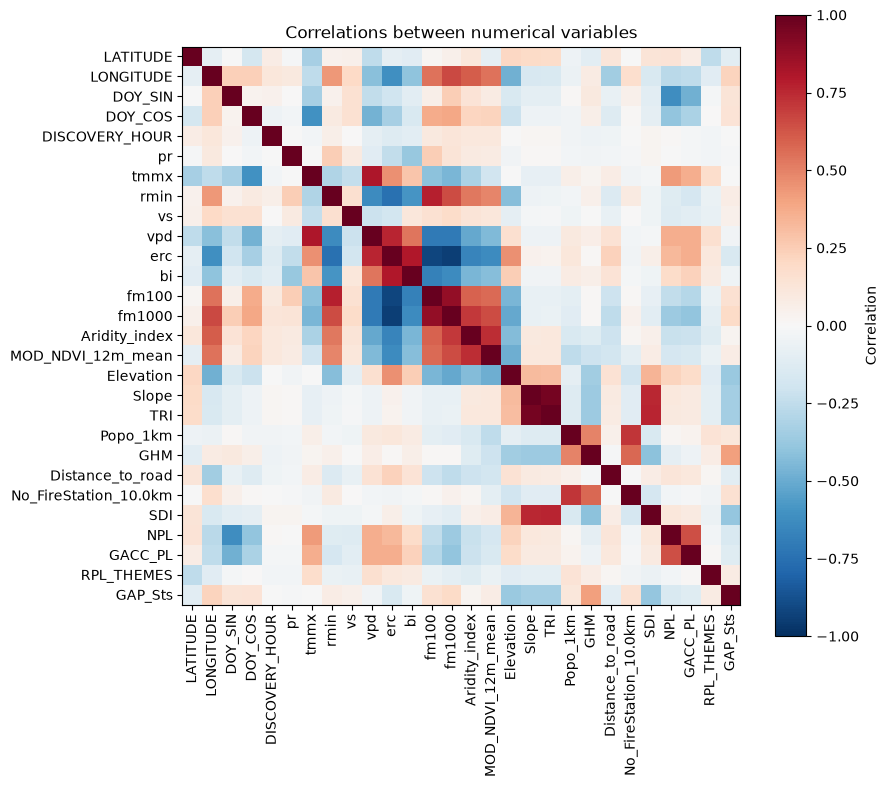

In [8]:
corr = X[NUM_FEATURES].corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM_FEATURES)), NUM_FEATURES, rotation=90)
ax.set_yticks(range(len(NUM_FEATURES)), NUM_FEATURES)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlations between numerical variables")
plt.tight_layout()
plt.show()

The figure above shows groups of highly correlated variables:

- slope and terrain ruggedness
- ERC and fuel moisture
- maximum temperature and vapour pressure deficit
- national preparedness level and season
- aridity and NDVI
- population density and number of fire stations
- suppression difficulty and terrain
- national and regional preparedness levels

These redundancies can make a linear model unstable, so we may use regularisation or keep one variable per group. Decision trees are less sensitive to this.

## 5. Planned preprocessing

* **Missing values:** replaced by the median of each variable, which is not affected by extreme values (mainly `DISCOVERY_HOUR`, 24% missing, and `Distance_to_road`, 31%).
* **Outliers:** kept, because extreme values (heavy rain, dense cities) are real observations.
* **Categorical variables:** `Land_Cover_1km_main` and `FRG_1km_main` are codes, not quantities, so they are one-hot encoded (one 0/1 column per class).
* **Scaling:** numerical variables are standardised (mean 0, standard deviation 1), because their scales are very different (see the table in section 4).
* **Class imbalance:** rare classes (big fires) get a higher weight during training, otherwise the model would mostly predict the two majority classes.
* **Additional features:** the derived variables of section 3 (cyclical day of year, hour, mean NDVI, main land cover and fire regime within 1 km).

* **Subsampling:** see section 6 (training set only).

All steps are fitted on the training set only, to avoid leakage into the test set.

## 6. Evaluation protocol

**Train / test split.** A random split would put fires from the same day and place in both the train and the test set, which would inflate the scores. A split by weeks does not solve it either: a drought or a storm lasting over a Sunday and a Monday gives almost identical fires on both sides of the boundary.  
We therefore **split by year**: train = 2019, test = 2020. The model learns from the past and is tested on a year it has never seen, which is also the real use case (predicting next year's fires). The test set is used only once, at the end, and keeps its real class distribution. The table below shows the number of fires per class in each set (before subsampling).

In [9]:
from sklearn.model_selection import StratifiedGroupKFold

year = pd.to_datetime(df["DISCOVERY_DATE"]).dt.year
month = pd.to_datetime(df["DISCOVERY_DATE"]).dt.month
is_test = year == 2020

pd.crosstab(is_test.map({False: "train (2019)", True: "test (2020)"}), y).rename(columns=dict(enumerate(CLASSES)))

size_class,very small (A),small (B),medium (C),medium-large (D),large (E-G)
DISCOVERY_DATE,,,,,
test (2020),34716,30327,5797,964,1048
train (2019),30388,25321,4693,717,664


The table above shows that the test set (2020) holds 54% of the fires (72,852) against 46% for the training set (61,783, before subsampling), with similar class proportions in both years (for example 1.4% of large fires in 2020 against 1.1% in 2019).

In [10]:
# Subsampling of the training set only: keep all medium/large fires (C, D, E-G), draw N_AB fires among A and B
N_AB, SEED = 20_000, 42
train_idx = df.index[~is_test]
ab = train_idx[y.loc[train_idx].isin([0, 1])]
keep = train_idx.difference(ab).union(pd.Index(np.random.RandomState(SEED).choice(ab, N_AB, replace=False)))
train_idx = keep.sort_values()
test_idx = df.index[is_test]

# 5-fold CV inside the training year, each fold made of whole months
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(train_idx, y.loc[train_idx], groups=month.loc[train_idx]))

pd.DataFrame({"train (subsampled)": y.loc[train_idx].value_counts(), "test": y.loc[test_idx].value_counts()}).sort_index().rename(index=dict(enumerate(CLASSES)))

,train (subsampled),test
size_class,,
very small (A),10885,34716
small (B),9115,30327
medium (C),4693,5797
medium-large (D),717,964
large (E-G),664,1048


**Subsampling (training set only).** Training on two years of data would make the hyperparameter search slow for some algorithms (SVM, k-nearest neighbours). We keep all medium, medium-large and large fires (C, D, E-G) and draw at random 20,000 fires among the very small and small ones (A, B), which make up 90% of the data. This reduces both the computing time and the class imbalance. The seed is fixed (`random_state=42`). The test set is never subsampled.

**Hyperparameter tuning.** 5-fold cross-validation inside the training year (2019) only, with `StratifiedGroupKFold`: each fold is made of whole months (no leakage between folds) and keeps similar class proportions. The test year (2020) is used only once, at the end.

**Model comparison.** A `DummyClassifier` baseline and two algorithms, evaluated with the same folds and the same test set. Train and test scores are both reported to detect overfitting.

**Metrics (3):**
* **Accuracy**: share of fires that are correctly classified. It is a bit misleading here because, with our class imbalance, a model can get a good score by always predicting "very small". We use it to compare our models with the dummy baseline.
* **Balanced accuracy**: for each class, the share of its fires that are correctly classified, averaged over the 5 classes. Every class counts the same, so a model that ignores the large fires gets a low score.
* **Macro F1**: for each class, the F1 score combines two errors: missed fires (a large fire predicted as small) and false alarms (a small fire predicted as large). The macro F1 is the average over the 5 classes, so it stays low if the model does badly on the rare classes.

## Use of AI

Claude was used to help us generate the code and understand some features.